Numpy arrays vs python list: -

In [2]:
import numpy as np

In [1]:
#speed: -
#list 
import time
a = [i for i in range(10000000)]
b = [i for i in range(10000000, 20000000)]
c = []

start = time.time()
for i in range(len(a)):
    c.append(a[i]+b[i])

print(time.time() - start)

1.5052757263183594


In [3]:
a = np.arange(10000000)
b = np.arange(10000000, 20000000)

start = time.time()
c = a+b
print(time.time()-start)

0.14264154434204102


In [ ]:
#memory : -
import sys
a = [i for i in range(10000000)]
print(sys.getsizeof(a))

89095160


In [8]:
b = np.arange(10000000, dtype='int32')
print(sys.getsizeof(b))

40000112


Advanced Indexing: -

In [11]:
a= np.arange(12).reshape(4, 3)
print(a)

[[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]


In [ ]:
#Fancy indexing: -  (mostly used with pandas for reading the datasets)
#If we want 1st, 3rd and 4th row
print(a[[0, 2, 3], :])      #We pass a list of rows or column which we need

[[ 0  1  2]
 [ 6  7  8]
 [ 9 10 11]]


In [18]:
a= np.arange(24).reshape(6, 4)
print(a)
print()

#If we want to print 1st, 3rd, 4th and last row
print(a[[0, 2, 3, -1], :])
print()

#if we want 1st, 3rd and 4th column
print(a[:, [0, 2, 3]])

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]
 [16 17 18 19]
 [20 21 22 23]]

[[ 0  1  2  3]
 [ 8  9 10 11]
 [12 13 14 15]
 [20 21 22 23]]

[[ 0  2  3]
 [ 4  6  7]
 [ 8 10 11]
 [12 14 15]
 [16 18 19]
 [20 22 23]]


In [20]:
#Boolean indexing: -(Imp for pandas as this is requirement based indexing)
a = np.random.randint(1, 100, 24).reshape(6, 4)
print(a)

[[71 39 30  1]
 [47 64 11 68]
 [23 42  6 45]
 [91 37 27 88]
 [99 13 54 62]
 [63 64 35 83]]


In [ ]:
#Finding numbers greater than 50
print(a[a>50])

#Finding numbers greater then 50 and even
print(a[(a>50) & (a%2==0)])     #We used bitwise and(&) as we are working with boolean.

[71 64 68 91 88 99 54 62 63 64 83]
[64 68 88 54 62 64]


Broadcasting: -
The term broadcasting describes how NumPy treats arrays with different shapes during arithmetic operations.
The smaller array is “broadcast” across the larger array so that they have compatible shapes for performing operations.

In [28]:
#same shape: -
a = np.arange(6).reshape(2, 3)
b = np.arange(6, 12).reshape(2, 3)

print(a)
print()

print(b)
print()

print(a+b)  #this can be done directly 

[[0 1 2]
 [3 4 5]]

[[ 6  7  8]
 [ 9 10 11]]

[[ 6  8 10]
 [12 14 16]]


In [ ]:
#different shape
a = np.arange(6).reshape(2, 3)
b = np.arange(3).reshape(1, 3)

print(a)
print()

print(b)
print()

print(a+b)      #This is done due to broadcast.

[[0 1 2]
 [3 4 5]]

[[0 1 2]]

[[0 2 4]
 [3 5 7]]


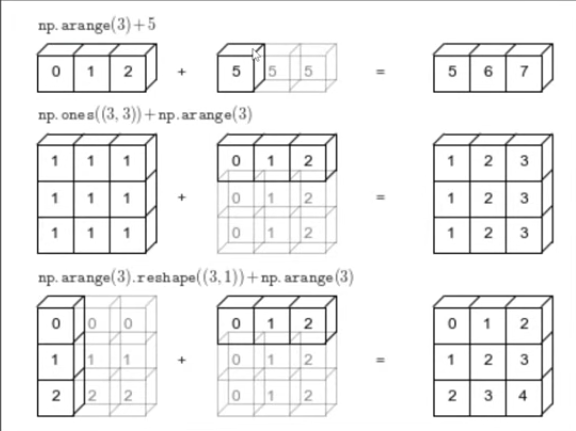

Rules of broadcasting: -
1) Make the two arrays have the same number of dimensions.
   If the numbers of dimensions of the two arrays are different, add new dimensions with size 1 to the head of the array with the smaller dimension.

2) Make each dimension of the two arrays the same size.
    If the sizes of each dimension of the two arrays do not match, dimensions with size 1 are stretched to the size of the other array.
    If there is a dimension whose size is not 1 in either of the two arrays, it cannot be broadcasted, and an error is raised.


In [ ]:
#ex: - (4,3) and (3) then (3) -> (1, 3) Adding one to the head
#(1, 3) -> (4, 3)
#hence broadcasting can be done


#ex: - (3, 4) and (3)
#(3) -> (1, 3) -> (3, 3)
#Here (3, 3) and (3, 4) are not same hence can be broadcasted.

#ex: - (1, 4) and (3, 1)
#(1, 4) -> (3, 4)
#(3, 1) -> (3, 4)
#Hence broadcasting can be done

#Can only change the ones.

In [3]:
a = np.arange(12).reshape(4, 3)
b = np.arange(3)
print(a+b)

[[ 0  2  4]
 [ 3  5  7]
 [ 6  8 10]
 [ 9 11 13]]


In [4]:
a = np.arange(12).reshape(3, 4)
b = np.arange(3)
print(a+b)

ValueError: operands could not be broadcast together with shapes (3,4) (3,) 

In [5]:
a = np.arange(16).reshape(4, 4)
b = np.arange(4).reshape(2 ,2)
print(a+b)

ValueError: operands could not be broadcast together with shapes (4,4) (2,2) 

Working with Mathematical formulas: -

In [6]:
#sigmoid: - 1/(1+e^-z)  and z=wixi + b
def sigmoid(array):
    return 1/(1+np.exp(-(array)))

a = np.arange(100)
print(sigmoid(a))

[0.5        0.73105858 0.88079708 0.95257413 0.98201379 0.99330715
 0.99752738 0.99908895 0.99966465 0.99987661 0.9999546  0.9999833
 0.99999386 0.99999774 0.99999917 0.99999969 0.99999989 0.99999996
 0.99999998 0.99999999 1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.        

In [7]:
#mean squared error: - 
actual = np.random.randint(1, 50, 25)
predicted = np.random.randint(1, 50, 25)

print(actual)
print()
print(predicted)

[12 28 33  9 18 46 44 21 36 11  8 45 13  9 49 13 31 10 36 43 28 30 24 35
 10]

[49 48 41 46 37 22 40 31 37 10 49  1 27  4  9 22 26 35 17 27 19 41 49 32
 19]


In [9]:
def MSE(actual, predicted):
    return np.mean((actual-predicted)**2)

print(MSE(actual, predicted))

478.4


Working with missing values: -

In [ ]:
#np.nan -> To pass missing value, we use np.nan
a = np.array([1, 2, 3, 4, np.nan, 6])
print(a)

[ 1.  2.  3.  4. nan  6.]


In [ ]:
#so we remove the null values
print(np.isnan(a))     #This returns a boolean array where null value is true

#Hence we use boolean indexing to remove the null values
a[~(np.isnan(a))]       #removes all the missing values

[False False False False  True False]


array([1., 2., 3., 4., 6.])

Plotting graphs: -

In [6]:
import matplotlib.pyplot as plt

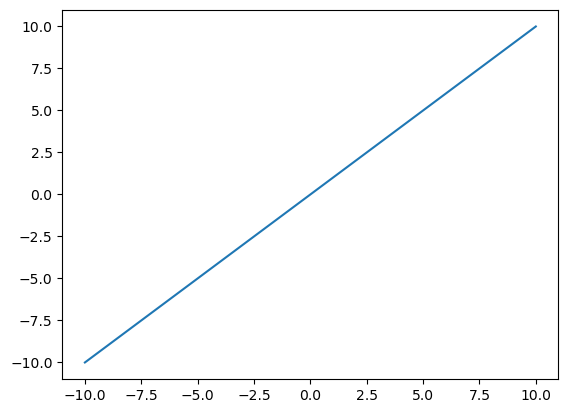

In [7]:
#plotting x = y
x = np.linspace(-10, 10, 100)
y = x

plt.plot(x, y)

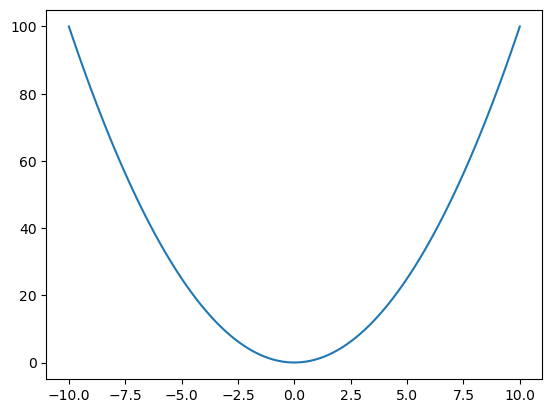

In [8]:
#plotting y = x^2
x = np.linspace(-10, 10, 100)
y = x**2
plt.plot(x, y)

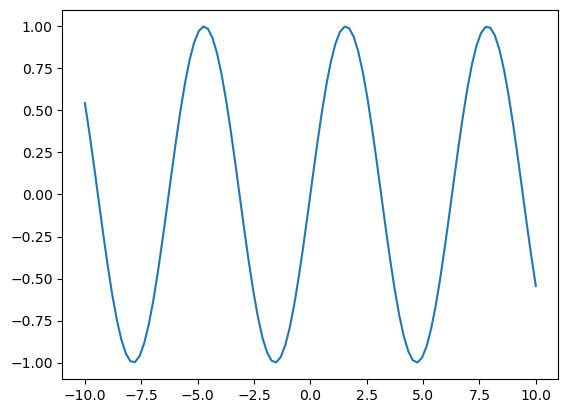

In [9]:
#plotting y = sinx
x = np.linspace(-10, 10, 100)
y = np.sin(x)
plt.plot(x, y)

/tmp/ipykernel_19726/3989772061.py:3: RuntimeWarning: invalid value encountered in log
  y = x * np.log(x)


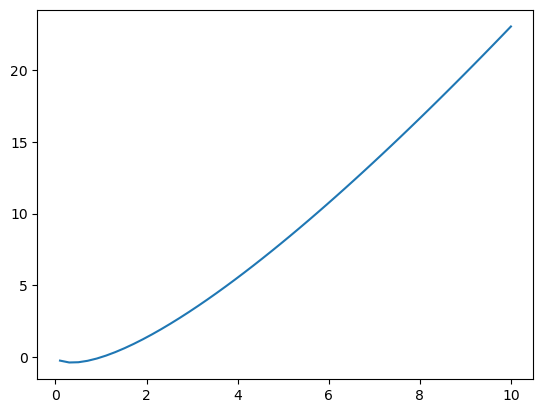

In [11]:
# y = xlog(x)
x = np.linspace(-10, 10, 100)
y = x * np.log(x)
plt.plot(x, y)

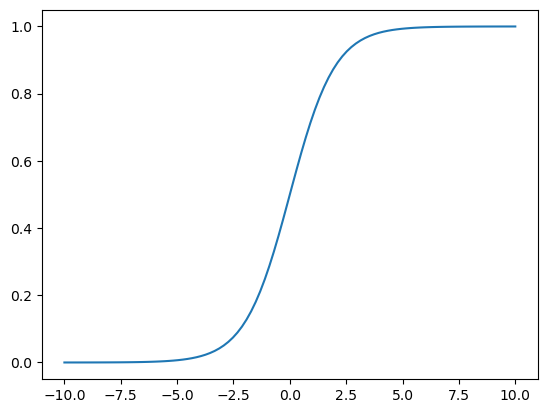

In [12]:
#plotting sigmoid graph
x = np.linspace(-10, 10, 100)
y = 1/(1+np.exp(-(x)))
plt.plot(x, y)